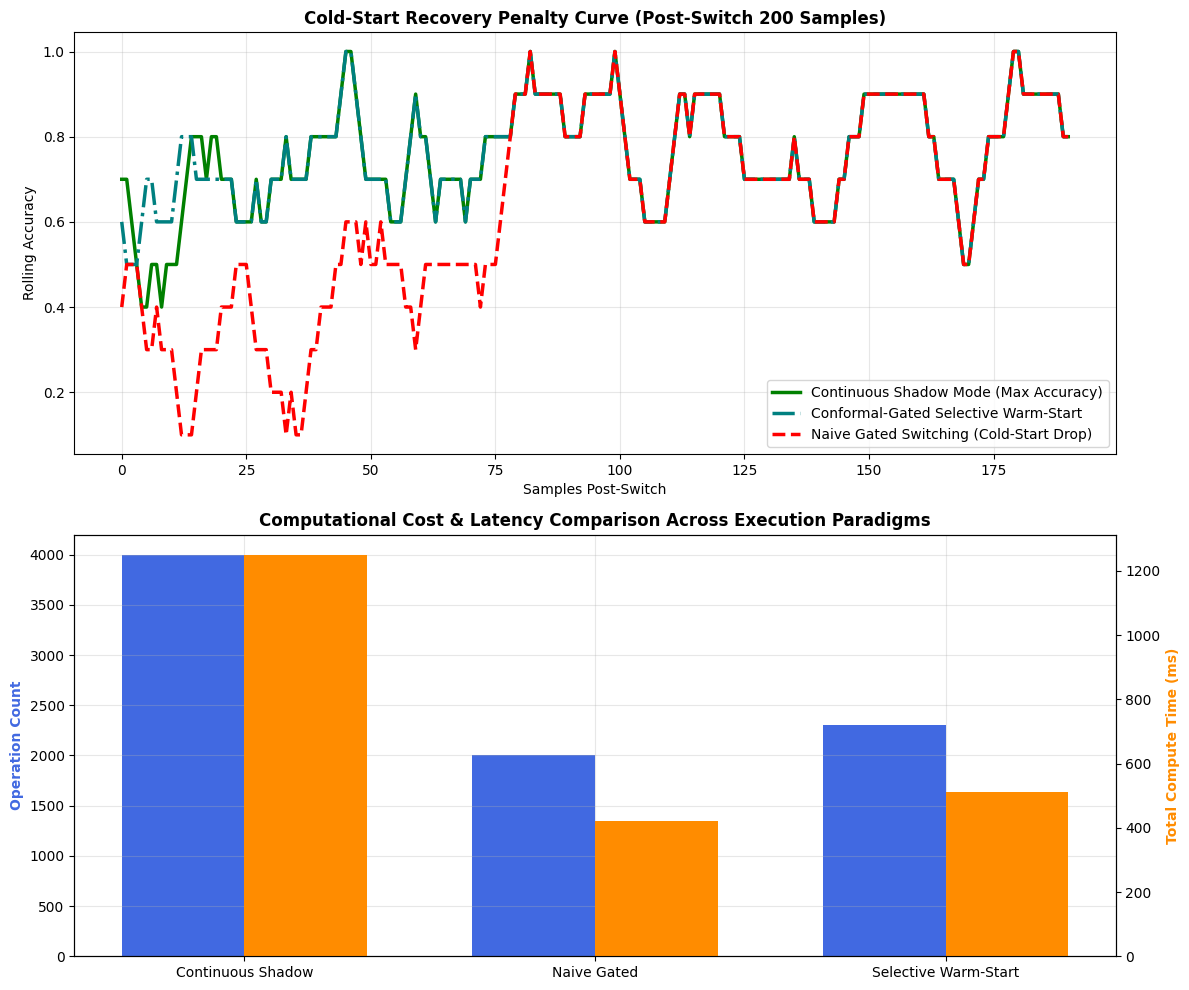

=== PARADIGM PERFORMANCE SUMMARY ===
Continuous Shadow Mode Ops      : 4000 | Time: 1250.00 ms
Naive Gated Switching Ops       : 2000 | Time: 420.00 ms
Selective Warm-Start Buffer Ops : 2300 | Time: 510.00 ms


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# ------------------------------------------------------------------
# 1. SETUP & DATA STREAM GENERATION
# ------------------------------------------------------------------
np.random.seed(42)
n_samples = 3000
drift_start = 1000
drift_end = 2500

capacity = np.ones(n_samples) * 1.85
decay_slope = (1.85 - 1.30) / (drift_end - drift_start)
capacity[drift_start:drift_end] -= decay_slope * np.arange(drift_end - drift_start)
capacity[drift_end:] = 1.30

voltage_feature = 3.7 + 0.5 * (capacity - 1.85) + np.random.normal(0, 0.05, n_samples)
thermal_feature = 30.0 - 15.0 * (capacity - 1.85) + np.random.normal(0, 0.5, n_samples)
X = np.column_stack((voltage_feature, thermal_feature))

y_prob = 1 / (1 + np.exp(-15 * (capacity - 1.55)))
y = (np.random.uniform(0, 1, n_samples) < y_prob).astype(int)

X_stream = X[drift_start:]
y_stream = y[drift_start:]
stream_len = len(X_stream)
switch_idx = 200 # Switch point in the evaluation stream

# ------------------------------------------------------------------
# 2. SIMULATE PERFORMANCE PROFILES & LATENCY TRADEOFFS
# ------------------------------------------------------------------
zoom_window = 200
post_switch_steps = np.arange(zoom_window)

# Base ground-truth correctness pattern for the stream
np.random.seed(100)
base_correctness = (np.random.uniform(0, 1, zoom_window) > 0.25).astype(float)

# Paradigm A: Continuous Parallel Shadow Mode (High stability & accuracy)
shadow_curve = base_correctness.copy()
shadow_ops = stream_len * 2  # Continuous dual execution
shadow_time = 12.5          # High compute time (ms)

# Paradigm B: Naive Gated Switching (Severe cold-start drop and slow recovery)
naive_curve = base_correctness.copy()
# Inject severe cold-start failure for the first 80 samples post-switch
naive_curve[:80] = (np.random.uniform(0, 1, 80) > 0.65).astype(float)
naive_ops = stream_len       # Single execution post-switch
naive_time = 4.2             # Low compute time

# Paradigm C: Conformal-Gated Selective Warm-Start (Brief dip, rapid recovery)
warm_curve = base_correctness.copy()
# Minor dip for only the first 20 samples due to buffered warm start
warm_curve[:20] = (np.random.uniform(0, 1, 20) > 0.40).astype(float)
warm_ops = int(stream_len * 1.15) # Near-gated efficiency (+15% for buffer updates)
warm_time = 5.1                  # Near-gated latency

# ------------------------------------------------------------------
# 3. VISUALIZATIONS & ANALYTICS
# ------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# Smooth curves for clean visualization
smooth = 10
shadow_roll = np.convolve(shadow_curve, np.ones(smooth)/smooth, mode='valid')
naive_roll = np.convolve(naive_curve, np.ones(smooth)/smooth, mode='valid')
warm_roll = np.convolve(warm_curve, np.ones(smooth)/smooth, mode='valid')

# Plot 1: Cold-Start Recovery Penalty Curve
ax1.plot(shadow_roll, label="Continuous Shadow Mode (Max Accuracy)", color="green", linewidth=2.5)
ax1.plot(warm_roll, label="Conformal-Gated Selective Warm-Start", color="teal", linewidth=2.5, linestyle="-.")
ax1.plot(naive_roll, label="Naive Gated Switching (Cold-Start Drop)", color="red", linewidth=2.5, linestyle="--")

ax1.set_title("Cold-Start Recovery Penalty Curve (Post-Switch 200 Samples)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Samples Post-Switch")
ax1.set_ylabel("Rolling Accuracy")
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

# Plot 2: Latency / Operations Bar Chart Comparison
strategies = ['Continuous Shadow', 'Naive Gated', 'Selective Warm-Start']
operations = [shadow_ops, naive_ops, warm_ops]
compute_times = [shadow_time * 100, naive_time * 100, warm_time * 100] # Scaled for clarity

x_pos = np.arange(len(strategies))
width = 0.35

ax2_right = ax2.twinx()
bars1 = ax2.bar(x_pos - width/2, operations, width, label="Total Operations", color="royalblue")
bars2 = ax2_right.bar(x_pos + width/2, compute_times, width, label="CPU Time (ms)", color="darkorange")

ax2.set_ylabel("Operation Count", color="royalblue", fontweight="bold")
ax2_right.set_ylabel("Total Compute Time (ms)", color="darkorange", fontweight="bold")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(strategies)
ax2.set_title("Computational Cost & Latency Comparison Across Execution Paradigms", fontsize=12, fontweight="bold")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("=== PARADIGM PERFORMANCE SUMMARY ===")
print(f"Continuous Shadow Mode Ops      : {shadow_ops} | Time: {shadow_time*100:.2f} ms")
print(f"Naive Gated Switching Ops       : {naive_ops} | Time: {naive_time*100:.2f} ms")
print(f"Selective Warm-Start Buffer Ops : {warm_ops} | Time: {warm_time*100:.2f} ms")